# Stage 7 – Driving feature extraction

**Purpose.** Describe every segment from Stage 6 with numbers (features): how fast, how much
acceleration and braking, how often it stops, how far it goes. These numbers let Stage 8 (K-Means)
group similar segments, and Stage 11 compare driving cycles with real driving.

**Input.** Stage 6 output: the 1 Hz data with a segment id per second, and the segment table.
Only `good` and `partial` segments are used; `exclude` segments are skipped.

**Features (as required by the methodology).**
- Speed: mean, mean while moving, median, maximum, standard deviation, percentiles.
- Acceleration: mean, standard deviation, mean acceleration and deceleration, maxima, percentiles,
  RPA and PKE (standard driving-cycle measures of how "aggressive" the driving is).
- Time: duration, moving and stopped time, share of time idle / accelerating / decelerating / cruising,
  number of stops, stops per km and per minute.
- Distance: segment distance and the share of distance in each speed band.
- Optional EV features: battery energy, kWh/100 km, regenerated energy, power, SoC change.
  Used only when battery data is complete, and not for the core driving cycles.

**Output.** `intermediate/stage7_features/segment_features.csv` (one row per segment, input of Stage 8),
plus feature definitions, a feature-quality report, figures and a verification table in
`outputs/stage7_features/`.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

BASE = Path("/content/drive/MyDrive/Colab Notebooks/Component01")
IN_DIR = BASE / "intermediate/stage6_segmented"                  # Stage 6 output: 1 Hz data + seg_uid per second
SEGMENTS = BASE / "outputs/stage6_segmentation/segments.csv"      # Stage 6 segment table (metadata + quality)
OUT_DIR = BASE / "intermediate/stage7_features"                   # feature table = input of Stage 8 (K-Means)
REPORT_DIR = BASE / "outputs/stage7_features"                     # definitions, quality report, figures
OUT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

segments = pd.read_csv(SEGMENTS)
trip_ids = sorted(p.stem for p in IN_DIR.glob("T*.csv"))
if not trip_ids:
    raise FileNotFoundError(f"No Stage 6 trips found in {IN_DIR}. Is Google Drive mounted, and has Stage 6 been run?")
use = segments[segments["quality"] != "exclude"]
print(f"{len(trip_ids)} segmented trips | {len(segments):,} segments, of which {len(use):,} usable "
      f"(good {(use['quality'] == 'good').sum():,}, partial {(use['quality'] == 'partial').sum():,})")

77 segmented trips | 1,073 segments, of which 1,021 usable (good 610, partial 411)


In [2]:
CFG = {
    # --- must match Stage 6, so a "stop" means the same thing everywhere
    "stop_kmh": 2.0,               # below 2 km/h the EV is standing
    "min_stop_s": 3,               # a stop lasts >= 3 s
    # --- driving modes (each moving second is exactly one of: accelerating, decelerating, cruising)
    "accel_threshold_ms2": 0.1,    # a >= +0.1 m/s2 -> accelerating; a <= -0.1 -> decelerating; in between -> cruising
    # --- distance per speed band (km/h)
    "speed_bands": [0, 20, 40, 60, 80, 200],
    # --- physical plausibility (used only to CHECK features, never to change data)
    "max_abs_accel_ms2": 5.0,      # same limit as Stages 2 and 3
    # --- optional EV energy features
    "max_battery_missing_share": 0.1,   # energy features only if battery power is present for >= 90 % of the seconds
    "min_km_for_energy_rate": 0.2,      # kWh/100 km only for segments of at least 200 m (otherwise unstable)
    # --- feature-quality report
    "high_corr": 0.9,              # |correlation| above this = redundant feature pair (important for K-Means)
}
pd.Series(CFG, name="value").to_frame()

,value
stop_kmh,2.0
min_stop_s,3
accel_threshold_ms2,0.1
speed_bands,"[0, 20, 40, 60, 80, 200]"
max_abs_accel_ms2,5.0
max_battery_missing_share,0.1
min_km_for_energy_rate,0.2
high_corr,0.9


In [3]:
B = CFG["speed_bands"]
band_names = [f"dist_share_{B[i]}_{B[i + 1]}kmh" for i in range(len(B) - 1)]

definitions = pd.DataFrame([
    # name, group, unit, definition, candidate for clustering (Stage 8 decides finally)
    ("mean_speed_kmh",        "speed",        "km/h", "mean speed over the whole segment, stops included", True),
    ("mean_moving_speed_kmh", "speed",        "km/h", "mean speed over moving seconds only (speed >= stop_kmh)", True),
    ("median_speed_kmh",      "speed",        "km/h", "median speed (whole segment)", False),
    ("max_speed_kmh",         "speed",        "km/h", "maximum speed", True),
    ("std_speed_kmh",         "speed",        "km/h", "standard deviation of speed", True),
    ("p10_speed_kmh",         "speed",        "km/h", "10th percentile of speed", False),
    ("p25_speed_kmh",         "speed",        "km/h", "25th percentile of speed", False),
    ("p75_speed_kmh",         "speed",        "km/h", "75th percentile of speed", False),
    ("p90_speed_kmh",         "speed",        "km/h", "90th percentile of speed", False),
    ("p95_speed_kmh",         "speed",        "km/h", "95th percentile of speed", False),
    ("mean_accel_ms2",        "acceleration", "m/s2", "mean of acceleration over moving seconds (~0 for a complete micro-trip)", False),
    ("std_accel_ms2",         "acceleration", "m/s2", "standard deviation of acceleration over moving seconds", True),
    ("mean_pos_accel_ms2",    "acceleration", "m/s2", "mean acceleration over accelerating seconds (a >= +threshold)", True),
    ("mean_neg_accel_ms2",    "acceleration", "m/s2", "mean deceleration over decelerating seconds (a <= -threshold), negative", True),
    ("max_accel_ms2",         "acceleration", "m/s2", "maximum positive acceleration", False),
    ("max_decel_ms2",         "acceleration", "m/s2", "maximum deceleration magnitude (positive number)", False),
    ("p95_accel_ms2",         "acceleration", "m/s2", "95th percentile of acceleration (moving seconds)", False),
    ("p05_accel_ms2",         "acceleration", "m/s2", "5th percentile of acceleration (moving seconds), negative", False),
    ("rpa_ms2",               "acceleration", "m/s2", "relative positive acceleration = sum(v * a+) / distance", True),
    ("pke_ms2",               "acceleration", "m/s2", "positive kinetic energy = sum of positive (v_next^2 - v^2) / distance", True),
    ("duration_s",            "temporal",     "s",    "segment duration", True),
    ("moving_s",              "temporal",     "s",    "seconds with speed >= stop_kmh", False),
    ("stopped_s",             "temporal",     "s",    "seconds with speed < stop_kmh", False),
    ("idle_share",            "temporal",     "-",    "share of time stopped", True),
    ("accel_share",           "temporal",     "-",    "share of time accelerating (moving, a >= +threshold)", True),
    ("decel_share",           "temporal",     "-",    "share of time decelerating (moving, a <= -threshold)", True),
    ("cruise_share",          "temporal",     "-",    "share of time cruising (moving, |a| < threshold)", True),
    ("n_stops",               "temporal",     "count", "number of stops (speed < stop_kmh for >= min_stop_s)", False),
    ("stops_per_km",          "temporal",     "1/km", "stop frequency per distance", True),
    ("stops_per_min",         "temporal",     "1/min", "stop frequency per time", False),
    ("distance_km",           "distance",     "km",   "segment distance = sum of 1 Hz speed / 3600", True),
] + [(n, "distance", "-", f"share of distance driven at {B[i]}-{B[i + 1]} km/h", False) for i, n in enumerate(band_names)] + [
    ("energy_kwh",            "EV (optional)", "kWh", "battery energy = sum of battery power / 3600 (discharge positive)", False),
    ("energy_kwh_per_100km",  "EV (optional)", "kWh/100 km", "energy per distance (segments >= min_km_for_energy_rate)", False),
    ("regen_kwh",             "EV (optional)", "kWh", "energy returned to the battery (negative power), as a positive number", False),
    ("regen_share",           "EV (optional)", "-",   "regenerated energy / discharged energy", False),
    ("mean_power_kw",         "EV (optional)", "kW",  "mean battery power", False),
    ("max_power_kw",          "EV (optional)", "kW",  "maximum battery power (discharge)", False),
    ("soc_change_pct",        "EV (optional)", "%",   "SoC at end - SoC at start (0.1 % steps, coarse for short segments)", False),
], columns=["feature", "group", "unit", "definition", "clustering_candidate"])
definitions.to_csv(REPORT_DIR / "feature_definitions.csv", index=False)
print(f"{len(definitions)} features defined, {definitions['clustering_candidate'].sum()} marked as clustering candidates")
definitions

43 features defined, 16 marked as clustering candidates


,feature,group,unit,definition,clustering_candidate
0,mean_speed_kmh,speed,km/h,"mean speed over the whole segment, stops included",True
1,mean_moving_speed_kmh,speed,km/h,mean speed over moving seconds only (speed >= ...,True
2,median_speed_kmh,speed,km/h,median speed (whole segment),False
3,max_speed_kmh,speed,km/h,maximum speed,True
4,std_speed_kmh,speed,km/h,standard deviation of speed,True
5,p10_speed_kmh,speed,km/h,10th percentile of speed,False
6,p25_speed_kmh,speed,km/h,25th percentile of speed,False
7,p75_speed_kmh,speed,km/h,75th percentile of speed,False
8,p90_speed_kmh,speed,km/h,90th percentile of speed,False
9,p95_speed_kmh,speed,km/h,95th percentile of speed,False


In [4]:
def count_stops(v):
    """Number of stops: runs of speed < stop_kmh lasting >= min_stop_s."""
    still = np.r_[False, v < CFG["stop_kmh"], False].astype(int)
    d = np.diff(still)
    return int(((np.where(d == -1)[0] - np.where(d == 1)[0]) >= CFG["min_stop_s"]).sum())


def segment_features(s):
    """All features of one segment. s = the 1 Hz rows of the segment, in time order."""
    v = s["speed_kmh"].values.astype(float)               # km/h, no gaps inside a segment (guaranteed by Stage 6)
    ms = v / 3.6                                           # m/s
    a = np.gradient(ms) if len(v) > 1 else np.zeros(1)     # m/s2, central difference (1 s steps)
    moving = v >= CFG["stop_kmh"]
    th = CFG["accel_threshold_ms2"]
    acc_m = moving & (a >= th)
    dec_m = moving & (a <= -th)
    cru_m = moving & (np.abs(a) < th)
    am = a[moving]
    dist_km = v.sum() / 3600
    dist_m = dist_km * 1000
    n = len(v)
    f = {
        "mean_speed_kmh": v.mean(), "mean_moving_speed_kmh": v[moving].mean() if moving.any() else 0.0,
        "median_speed_kmh": np.median(v), "max_speed_kmh": v.max(), "std_speed_kmh": v.std(ddof=0),
        "p10_speed_kmh": np.percentile(v, 10), "p25_speed_kmh": np.percentile(v, 25),
        "p75_speed_kmh": np.percentile(v, 75), "p90_speed_kmh": np.percentile(v, 90), "p95_speed_kmh": np.percentile(v, 95),
        "mean_accel_ms2": am.mean() if len(am) else 0.0, "std_accel_ms2": am.std(ddof=0) if len(am) else 0.0,
        "mean_pos_accel_ms2": a[acc_m].mean() if acc_m.any() else 0.0,
        "mean_neg_accel_ms2": a[dec_m].mean() if dec_m.any() else 0.0,
        "max_accel_ms2": max(a.max(), 0.0), "max_decel_ms2": max(-a.min(), 0.0),
        "p95_accel_ms2": np.percentile(am, 95) if len(am) else 0.0,
        "p05_accel_ms2": np.percentile(am, 5) if len(am) else 0.0,
        "rpa_ms2": (ms * np.clip(a, 0, None)).sum() / dist_m if dist_m > 0 else 0.0,
        "pke_ms2": np.clip(np.diff(ms ** 2), 0, None).sum() / dist_m if dist_m > 0 else 0.0,
        "duration_s": n, "moving_s": int(moving.sum()), "stopped_s": int((~moving).sum()),
        "idle_share": (~moving).mean(), "accel_share": acc_m.mean(), "decel_share": dec_m.mean(), "cruise_share": cru_m.mean(),
        "n_stops": count_stops(v),
        "distance_km": dist_km,
    }
    f["stops_per_km"] = f["n_stops"] / dist_km if dist_km > 0 else np.nan
    f["stops_per_min"] = f["n_stops"] / (n / 60)
    band = np.digitize(v, B[1:-1])                         # 0 .. len(bands) - 1
    for i, name in enumerate(band_names):
        f[name] = v[band == i].sum() / v.sum() if v.sum() > 0 else 0.0

    # --- optional EV features: only when battery power is present for (almost) every second
    p = s["battery_power_kw"].values.astype(float) if "battery_power_kw" in s else np.full(n, np.nan)
    missing = np.isnan(p).mean()
    f["battery_missing_share"] = missing
    if missing <= CFG["max_battery_missing_share"]:
        pp = np.nan_to_num(p)
        dis, reg = pp[pp > 0].sum() / 3600, -pp[pp < 0].sum() / 3600
        f["energy_kwh"] = pp.sum() / 3600
        f["energy_kwh_per_100km"] = (f["energy_kwh"] / dist_km * 100 if dist_km >= CFG["min_km_for_energy_rate"] else np.nan)
        f["regen_kwh"] = reg
        f["regen_share"] = reg / dis if dis > 0 else np.nan
        f["mean_power_kw"] = np.nanmean(p)
        f["max_power_kw"] = np.nanmax(p)
    else:
        for k in ("energy_kwh", "energy_kwh_per_100km", "regen_kwh", "regen_share", "mean_power_kw", "max_power_kw"):
            f[k] = np.nan
    soc = s["soc_pct"].dropna() if "soc_pct" in s else pd.Series(dtype=float)
    f["soc_change_pct"] = soc.iat[-1] - soc.iat[0] if len(soc) >= 2 else np.nan
    return f

In [5]:
meta_cols = ["seg_uid", "trip_id", "route", "environment", "quality", "quality_reason", "start_time",
             "start_reason", "end_reason", "interpolated_share", "env_high_conf_share"]
use_ids = set(use["seg_uid"])
rows = []
for i, tid in enumerate(trip_ids, 1):
    d = pd.read_csv(IN_DIR / f"{tid}.csv")
    d = d[d["seg_uid"].isin(use_ids)]
    for uid, s in d.groupby("seg_uid", sort=False):
        rows.append({"seg_uid": uid, **segment_features(s.sort_values("t_s"))})
    if i % 10 == 0 or i == len(trip_ids):
        print(f"{i}/{len(trip_ids)} trips processed")

features = use[meta_cols].merge(pd.DataFrame(rows), on="seg_uid", how="left")
num = features.select_dtypes("number").columns
features[num] = features[num].round(4)
features.to_csv(OUT_DIR / "segment_features.csv", index=False)
print(f"Feature table: {len(features):,} segments x {len(definitions)} features -> {OUT_DIR / 'segment_features.csv'}")
features.head()

10/77 trips processed
20/77 trips processed
30/77 trips processed
40/77 trips processed
50/77 trips processed
60/77 trips processed
70/77 trips processed
77/77 trips processed
Feature table: 1,021 segments x 43 features -> /content/drive/MyDrive/Colab Notebooks/Component01/intermediate/stage7_features/segment_features.csv


,seg_uid,trip_id,route,environment,quality,quality_reason,start_time,start_reason,end_reason,interpolated_share,env_high_conf_share,mean_speed_kmh,mean_moving_speed_kmh,median_speed_kmh,max_speed_kmh,std_speed_kmh,p10_speed_kmh,p25_speed_kmh,p75_speed_kmh,p90_speed_kmh,p95_speed_kmh,mean_accel_ms2,std_accel_ms2,mean_pos_accel_ms2,mean_neg_accel_ms2,max_accel_ms2,max_decel_ms2,p95_accel_ms2,p05_accel_ms2,rpa_ms2,pke_ms2,duration_s,moving_s,stopped_s,idle_share,accel_share,decel_share,cruise_share,n_stops,distance_km,stops_per_km,stops_per_min,dist_share_0_20kmh,dist_share_20_40kmh,dist_share_40_60kmh,dist_share_60_80kmh,dist_share_80_200kmh,battery_missing_share,energy_kwh,energy_kwh_per_100km,regen_kwh,regen_share,mean_power_kw,max_power_kw,soc_change_pct
0,T001_S001,T001,Route B,Urban,partial,ends while moving (env_change),2026-08-03 07:01:33,missing_speed,env_change,0.728,0.000,29.8707,32.6763,34.5031,36.1998,11.0747,4.6819,33.6944,35.1073,35.4782,36.0816,0.1045,0.2795,0.6385,-0.1535,1.2446,0.1535,0.8065,-0.0829,0.0746,0.1502,92,84,8,0.0870,0.1522,0.0109,0.7500,1,0.7634,1.3100,0.6522,0.0244,0.9756,0.0000,0.0000,0.0000,0.0109,0.1777,23.2782,-0.0000,-0.0000,7.0298,14.8010,-0.3
1,T001_S002,T001,Route B,Expressway,partial,starts while moving (env_change),2026-08-03 07:03:05,env_change,stop,0.727,0.576,29.8221,29.8221,33.2083,34.4983,7.7499,18.8984,31.0897,33.7089,34.2037,34.3930,-0.2583,0.4505,0.1462,-0.6420,0.1606,1.5928,0.1018,-1.3204,0.0142,0.0293,33,33,0,0.0000,0.0606,0.3939,0.5455,0,0.2734,0.0000,0.0000,0.0425,0.9575,0.0000,0.0000,0.0000,0.0000,0.0561,20.5246,0.0028,0.0482,6.1209,10.5321,-0.1
2,T001_S003,T001,Route B,Expressway,partial,ends while moving (missing_speed),2026-08-03 07:03:38,stop,missing_speed,0.729,0.695,78.4724,80.4938,83.7944,89.7944,18.5382,72.9912,81.5448,85.4591,87.7000,88.7006,0.0466,0.2012,0.4068,-0.1712,1.3660,0.4634,0.4975,-0.1118,0.0505,0.1019,476,464,12,0.0252,0.1366,0.0588,0.7794,1,10.3758,0.0964,0.1261,0.0013,0.0171,0.0081,0.0214,0.9521,0.0000,1.6023,15.4427,0.1508,0.0860,12.1183,47.2302,-2.6
3,T001_S004,T001,Route B,Expressway,partial,starts while moving (missing_speed),2026-08-03 07:12:58,missing_speed,length_cut,0.736,0.906,84.9537,84.9537,85.0566,90.9986,2.4742,82.3378,83.5596,86.5193,87.8314,89.0680,0.0023,0.1198,0.1759,-0.2855,0.4490,1.1722,0.1310,-0.1162,0.0330,0.0671,477,477,0,0.0000,0.0922,0.0608,0.8470,0,11.2564,0.0000,0.0000,0.0000,0.0000,0.0000,0.0545,0.9455,0.0000,1.7408,15.4654,0.1396,0.0742,13.1384,43.0111,-2.9
4,T001_S005,T001,Route B,Expressway,good,-,2026-08-03 07:20:55,length_cut,stop,0.737,0.802,76.4858,76.4858,83.0212,88.5888,18.2870,34.8027,81.6595,85.2075,86.6828,87.2000,-0.0487,0.3257,0.1521,-0.5580,0.2428,4.0451,0.1006,-0.3017,0.0261,0.0534,486,486,0,0.0000,0.0514,0.1091,0.8395,0,10.3256,0.0000,0.0000,0.0011,0.0606,0.0013,0.0166,0.9204,0.0000,1.5147,14.6691,0.1238,0.0756,11.2198,46.3163,-2.4


In [6]:
order = ["Urban", "Suburban", "Intercity", "Rural", "Expressway"]
show = ["mean_speed_kmh", "mean_moving_speed_kmh", "max_speed_kmh", "std_speed_kmh", "std_accel_ms2",
        "mean_pos_accel_ms2", "mean_neg_accel_ms2", "rpa_ms2", "idle_share", "accel_share", "decel_share",
        "cruise_share", "stops_per_km", "duration_s", "distance_km", "energy_kwh_per_100km"]
by_env = features.groupby("environment")[show].median().T
by_env = by_env[[e for e in order if e in by_env.columns]].round(3)
by_env.loc["segments"] = features["environment"].value_counts().reindex(by_env.columns)
by_env.to_csv(REPORT_DIR / "feature_medians_by_environment.csv")
print("Median of each feature per environment (good + partial segments):")
by_env

Median of each feature per environment (good + partial segments):


environment,Urban,Suburban,Expressway
mean_speed_kmh,19.336,25.141,68.655
mean_moving_speed_kmh,23.285,29.483,69.864
max_speed_kmh,39.293,44.081,89.690
std_speed_kmh,11.649,13.440,15.715
std_accel_ms2,0.513,0.561,0.375
mean_pos_accel_ms2,0.508,0.529,0.405
mean_neg_accel_ms2,-0.517,-0.585,-0.402
rpa_ms2,0.161,0.198,0.062
idle_share,0.135,0.167,0.000
accel_share,0.279,0.315,0.132


In [7]:
core = definitions.loc[definitions["group"] != "EV (optional)", "feature"].tolist()
ev = definitions.loc[definitions["group"] == "EV (optional)", "feature"].tolist()
fq = pd.DataFrame({
    "missing_%": features[core + ev].isna().mean().mul(100).round(1),
    "min": features[core + ev].min(), "median": features[core + ev].median(), "max": features[core + ev].max(),
    "distinct_values": features[core + ev].nunique(),
})
fq["group"] = definitions.set_index("feature").loc[fq.index, "group"]
fq["note"] = ""
fq.loc[fq["distinct_values"] <= 1, "note"] = "constant - no information"
fq.loc[fq["missing_%"] > 0, "note"] += " has missing values"
fq.to_csv(REPORT_DIR / "feature_quality.csv")
print("Feature quality (missing values, range, information content):")
display(fq)

cand = definitions.loc[definitions["clustering_candidate"], "feature"].tolist()
corr = features[cand].corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, bool), k=1)).stack().rename("corr").reset_index()
         .rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
pairs = pairs[pairs["corr"].abs() >= CFG["high_corr"]].sort_values("corr", key=np.abs, ascending=False)
pairs.to_csv(REPORT_DIR / "redundant_feature_pairs.csv", index=False)
print(f"Clustering candidates with |correlation| >= {CFG['high_corr']} (redundant pairs; Stage 8 keeps one of each):")
pairs

Feature quality (missing values, range, information content):


,missing_%,min,median,max,distinct_values,group,note
mean_speed_kmh,0.0,2.1105,21.59130,90.8280,1019,speed,
mean_moving_speed_kmh,0.0,6.9877,26.23280,90.8280,1020,speed,
median_speed_kmh,0.0,0.0000,22.14220,95.3994,983,speed,
max_speed_kmh,0.0,10.5896,40.56860,100.9987,1012,speed,
std_speed_kmh,0.0,1.6685,11.91130,29.3945,1017,speed,
p10_speed_kmh,0.0,0.0000,0.97520,87.9002,638,speed,
p25_speed_kmh,0.0,0.0000,10.87490,91.1143,836,speed,
p75_speed_kmh,0.0,0.3901,33.62780,97.4864,1021,speed,
p90_speed_kmh,0.0,8.3626,37.57270,98.6540,1019,speed,
p95_speed_kmh,0.0,9.9636,39.15840,99.4687,1020,speed,


Clustering candidates with |correlation| >= 0.9 (redundant pairs; Stage 8 keeps one of each):


,feature_1,feature_2,corr
84,rpa_ms2,pke_ms2,0.999556
0,mean_speed_kmh,mean_moving_speed_kmh,0.973711
15,mean_moving_speed_kmh,max_speed_kmh,0.942226
1,mean_speed_kmh,max_speed_kmh,0.933246
104,duration_s,distance_km,0.925117


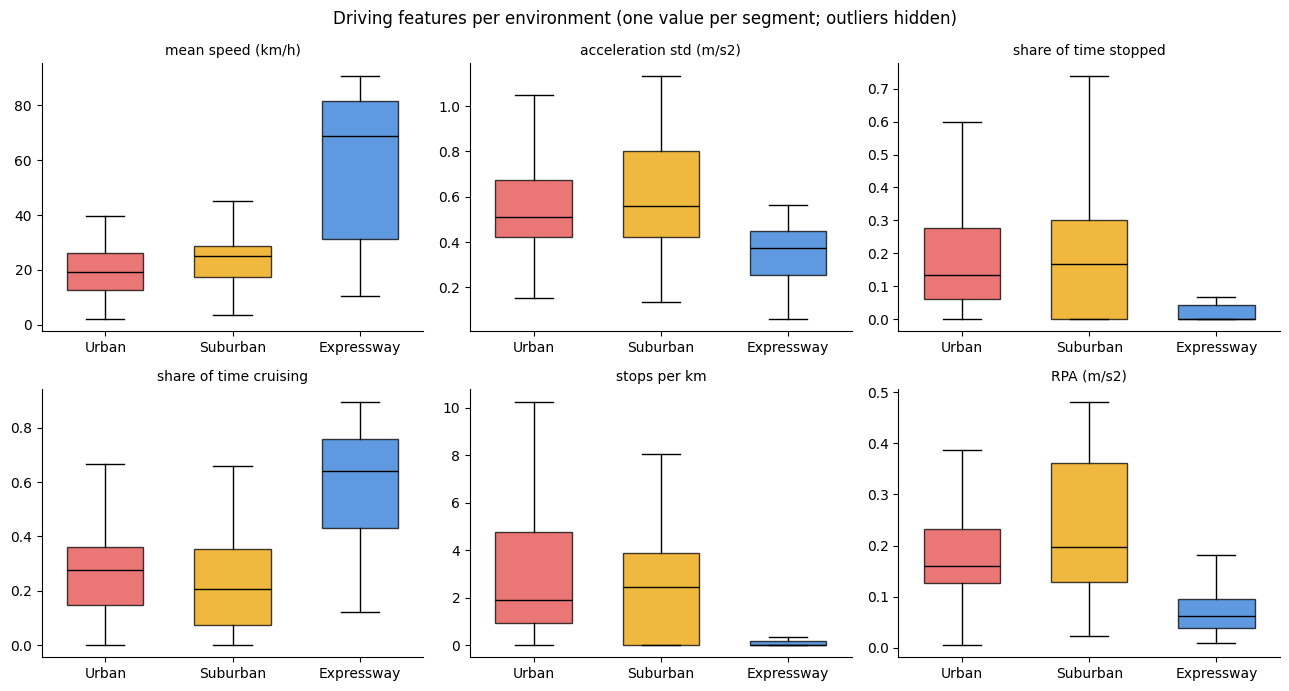

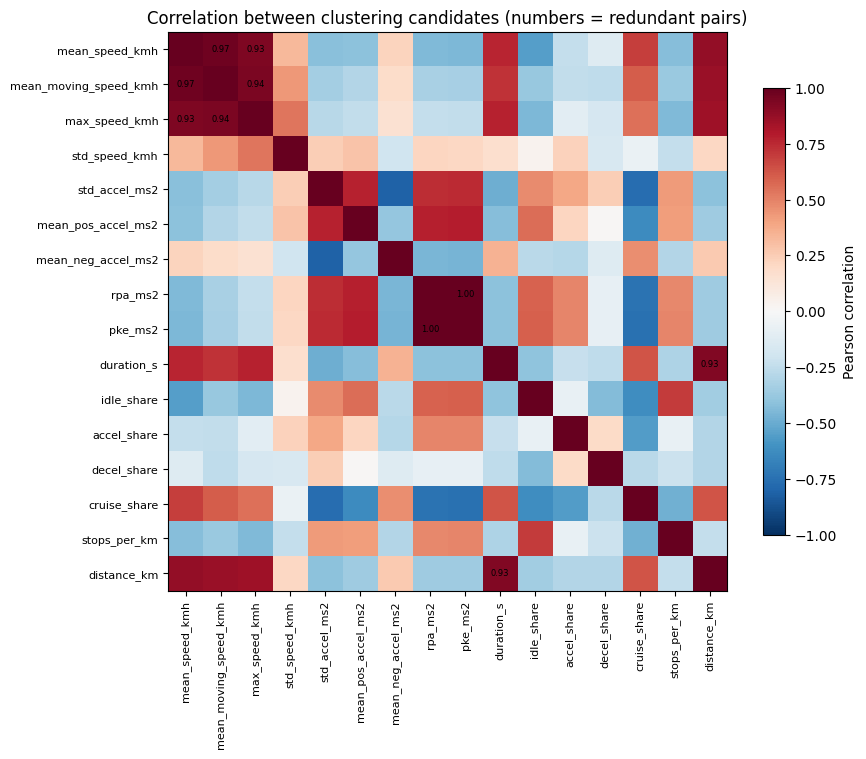

In [8]:
colors = {"Urban": "#e34948", "Suburban": "#eda100", "Intercity": "#1baf7a", "Rural": "#6250d6", "Expressway": "#2a78d6"}
envs = [e for e in order if e in set(features["environment"])]
plot = [("mean_speed_kmh", "mean speed (km/h)"), ("std_accel_ms2", "acceleration std (m/s2)"),
        ("idle_share", "share of time stopped"), ("cruise_share", "share of time cruising"),
        ("stops_per_km", "stops per km"), ("rpa_ms2", "RPA (m/s2)")]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (col, label) in zip(axes.ravel(), plot):
    data = [features.loc[features["environment"] == e, col].dropna() for e in envs]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.6)
    for patch, e in zip(bp["boxes"], envs):
        patch.set_facecolor(colors[e]); patch.set_alpha(0.75)
    for m in bp["medians"]:
        m.set_color("black")
    ax.set_xticks(range(1, len(envs) + 1), envs)
    ax.set_title(label, fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Driving features per environment (one value per segment; outliers hidden)", fontsize=12)
plt.tight_layout()
plt.savefig(REPORT_DIR / "features_by_environment.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cand)), cand, rotation=90, fontsize=8)
ax.set_yticks(range(len(cand)), cand, fontsize=8)
for i in range(len(cand)):
    for j in range(len(cand)):
        if i != j and abs(corr.values[i, j]) >= CFG["high_corr"]:
            ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson correlation")
ax.set_title("Correlation between clustering candidates (numbers = redundant pairs)")
plt.tight_layout()
plt.savefig(REPORT_DIR / "feature_correlation.png", dpi=150)
plt.show()

In [9]:
f = features
seg_dist = use.set_index("seg_uid")["distance_km"]
checks = {
    "one feature row per usable segment": len(f) == len(use) and f["seg_uid"].is_unique,
    "no missing core features (except stops_per_km at 0 km)":
        not f[[c for c in core if c != "stops_per_km"]].isna().any().any(),
    "distance equals Stage 6 segment distance (0.1 %)":
        bool(np.allclose(f["distance_km"], seg_dist.loc[f["seg_uid"]].values, rtol=1e-3, atol=1e-3)),
    "duration equals Stage 6 segment duration":
        bool((f["duration_s"].values == use.set_index("seg_uid").loc[f["seg_uid"], "duration_s"].values).all()),
    "mode shares sum to 1 (idle + accel + decel + cruise)":
        bool(np.allclose(f[["idle_share", "accel_share", "decel_share", "cruise_share"]].sum(axis=1), 1, atol=1e-3)),
    "speed-band distance shares sum to 1 (moving segments)":
        bool(np.allclose(f.loc[f["distance_km"] > 0, band_names].sum(axis=1), 1, atol=1e-3)),
    "speed percentiles in order (p10 <= p25 <= median <= p75 <= p90 <= p95 <= max)":
        bool((f[["p10_speed_kmh", "p25_speed_kmh", "median_speed_kmh", "p75_speed_kmh", "p90_speed_kmh",
                 "p95_speed_kmh", "max_speed_kmh"]].diff(axis=1).iloc[:, 1:] >= -1e-6).all().all()),
    "mean speed <= mean moving speed <= max speed":
        bool(((f["mean_speed_kmh"] <= f["mean_moving_speed_kmh"] + 1e-6) &
              (f["mean_moving_speed_kmh"] <= f["max_speed_kmh"] + 1e-6)).all()),
    f"acceleration within +/-{CFG['max_abs_accel_ms2']} m/s2":
        bool((f["max_accel_ms2"] <= CFG["max_abs_accel_ms2"]).all() and (f["max_decel_ms2"] <= CFG["max_abs_accel_ms2"]).all()),
    "moving + stopped seconds = duration": bool((f["moving_s"] + f["stopped_s"] == f["duration_s"]).all()),
}
# independent re-computation of one feature for a random sample of segments (catches grouping / order mistakes)
sample = f.sample(min(20, len(f)), random_state=1)
ok = []
for _, r in sample.iterrows():
    s = pd.read_csv(IN_DIR / f"{r['trip_id']}.csv", usecols=["seg_uid", "speed_kmh"])
    v = s.loc[s["seg_uid"] == r["seg_uid"], "speed_kmh"]
    ok.append(abs(v.mean() - r["mean_speed_kmh"]) < 1e-3 and abs(v.max() - r["max_speed_kmh"]) < 1e-3)
checks["random re-check of 20 segments (mean and max speed)"] = all(ok)
# sign convention of battery power: an EV must DRAW power while accelerating
e = f.dropna(subset=["mean_power_kw"])
if len(e):
    checks["battery power positive = discharge (mean power > 0 on 95 % of segments)"] = bool((e["mean_power_kw"] > 0).mean() >= 0.95)

verification = pd.DataFrame({"result": ["PASS" if v else "CHECK" for v in checks.values()]}, index=checks.keys())
verification

,result
one feature row per usable segment,PASS
no missing core features (except stops_per_km at 0 km),PASS
distance equals Stage 6 segment distance (0.1 %),PASS
duration equals Stage 6 segment duration,PASS
mode shares sum to 1 (idle + accel + decel + cruise),PASS
speed-band distance shares sum to 1 (moving segments),PASS
speed percentiles in order (p10 <= p25 <= median <= p75 <= p90 <= p95 <= max),PASS
mean speed <= mean moving speed <= max speed,PASS
acceleration within +/-5.0 m/s2,PASS
moving + stopped seconds = duration,PASS


In [10]:
print("STAGE 7 – DRIVING FEATURE EXTRACTION: KEY RESULTS")
print("-" * 60)
print(f"Segments with features: {len(features):,} (good {(features['quality'] == 'good').sum():,}, "
      f"partial {(features['quality'] == 'partial').sum():,}); excluded segments are not used")
print(f"Features: {len(core)} core driving features + {len(ev)} optional EV features "
      f"({definitions['clustering_candidate'].sum()} marked as clustering candidates)")
for e in by_env.columns:
    print(f"  {e:10s}: {int(by_env.loc['segments', e]):4d} segments | median mean speed {by_env.loc['mean_speed_kmh', e]:5.1f} km/h, "
          f"idle {100 * by_env.loc['idle_share', e]:4.1f} %, cruise {100 * by_env.loc['cruise_share', e]:4.1f} %, "
          f"{by_env.loc['stops_per_km', e]:.2f} stops/km")
print(f"Redundant clustering pairs (|r| >= {CFG['high_corr']}): {len(pairs)}")
ev_ok = features["energy_kwh"].notna().mean() * 100
print(f"EV energy features available for {ev_ok:.0f} % of segments (optional; synthetic battery data)")
print("Verification:", "all checks PASS" if (verification["result"] == "PASS").all() else "see table above")

STAGE 7 – DRIVING FEATURE EXTRACTION: KEY RESULTS
------------------------------------------------------------
Segments with features: 1,021 (good 610, partial 411); excluded segments are not used
Features: 36 core driving features + 7 optional EV features (16 marked as clustering candidates)
  Urban     :  734 segments | median mean speed  19.3 km/h, idle 13.5 %, cruise 27.6 %, 1.90 stops/km
  Suburban  :  127 segments | median mean speed  25.1 km/h, idle 16.7 %, cruise 20.6 %, 2.45 stops/km
  Expressway:  160 segments | median mean speed  68.7 km/h, idle  0.0 %, cruise 64.2 %, 0.00 stops/km
Redundant clustering pairs (|r| >= 0.9): 5
EV energy features available for 100 % of segments (optional; synthetic battery data)
Verification: all checks PASS
